# Data Analysis and Preprocessing

This section explores the SMS messages, prepares them for analysis, and compares several sampling strategies. The original `text` column is kept unchanged throughout the notebook.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler #n

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/dataset.csv")
df = pd.read_csv(DATA_PATH)

print("Loaded", len(df), "rows from", DATA_PATH)

df.head()
#df.label.value_counts()


Loaded 5574 rows from ../data/dataset.csv


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 1. Understanding the dataset

Each row represents one SMS message. `label` is the category we want to understand and later predict, while `text` contains the message itself. At this stage the dataset has one text column and one categorical label column; the numerical columns are created from the messages below.

In [2]:

print("Shape:", df.shape)

print("Columns:")
print(df.columns)

print("Data Types:")
print(df.dtypes)

print("Dataset Information:")
df.info()

print("Descriptive Statistics:")
display(df.describe(include="all"))

print("Text column: text")
print("Label column: label")


Shape: (5574, 2)
Columns:
Index(['label', 'text'], dtype='str')
Data Types:
label    str
text     str
dtype: object
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5574 non-null   str  
 1   text    5574 non-null   str  
dtypes: str(2)
memory usage: 543.0 KB
Descriptive Statistics:


,label,text
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


Text column: text
Label column: label


## 2. Missing values and duplicates

Missing text cannot be used for text analysis, so those rows will be removed. Missing labels cannot be used as targets, so they will also be removed. Exact duplicate records do not add new information and can bias class counts, so they will be dropped. The before/after shapes make the effect of cleaning explicit.

In [3]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

shape_before = df.shape

df = df.dropna()
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Before Cleaning:", shape_before)
print("After Cleaning:", df.shape)
print("Removed Rows:", shape_before[0] - df.shape[0])


Missing Values:
label    0
text     0
dtype: int64
Duplicate Rows: 403
Before Cleaning: (5574, 2)
After Cleaning: (5171, 2)
Removed Rows: 403


## 3. `loc` and `iloc`

`loc` is useful when the selection is based on a condition. `iloc` is useful when the position of the rows or columns is what matters. The `np.r_` example picks rows that are not next to each other. At this point the frame only has `label` and `text`, so the example is on rows.

In [4]:
# Select 5 spam messages
spam_preview = df.loc[df["label"] == "spam", ["label", "text"]]
display(spam_preview.head())

# Select first 3 rows and first 2 columns
display(df.iloc[:3, :2])

# Select first 5 rows
display(df.iloc[:5])

# rows 0 and 1, then skip ahead to rows 10 and 11
display(df.iloc[np.r_[0:2, 10:12]])


,label,text
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs a..."


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
10,ham,"I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today."
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs a..."


## 4. Transformations and feature creation

The following transformations are useful for SMS data: standardizing the label type, consolidating text whitespace, creating several numeric text features, encoding the label, and normalizing message length. The original message remains available in `text`.

In [5]:

df["label"] = df["label"].astype("category")
df["clean_text"] = df["text"].str.strip()
df["char_count"] = df["text"].str.len()
df["word_count"] = df["clean_text"].str.split().str.len()
df["unique_word_count"] = df["clean_text"].str.lower().str.split().apply(lambda x: len(set(x)))
df["avg_word_length"] = df["char_count"] / df["word_count"].clip(lower=1)
df["label_code"] = df["label"].cat.codes
scaler = MinMaxScaler()
df["char_count_normalized"] = scaler.fit_transform(df[["char_count"]]).ravel()
display(df.head())


,label,text,clean_text,char_count,word_count,unique_word_count,avg_word_length,label_code,char_count_normalized
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...","Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",111,20,20,5.550000,0,0.120044
1,ham,Ok lar... Joking wif u oni...,Ok lar... Joking wif u oni...,29,6,6,4.833333,0,0.029736
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,155,28,24,5.535714,1,0.168502
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor... U c already then say...,49,11,10,4.454545,0,0.051762
4,ham,"Nah I don't think he goes to usf, he lives around here though","Nah I don't think he goes to usf, he lives around here though",61,13,12,4.692308,0,0.064978


## 5. Sampling methods

Simple random sampling gives every row the same chance of selection. Stratified sampling preserves the label proportions by sampling within each label. For cluster sampling, messages are grouped into four length-based clusters and two complete clusters are selected. Because clusters are selected as groups, their class balance can differ from the full dataset.

In [6]:
RANDOM_STATE = 42
sample_size = min(500, len(df))

# Simple Random Sampling  كل صف عنده فرصة متساوية للاختيار
simple_sample = df.sample(
    n=sample_size,
    random_state=RANDOM_STATE
)

# Stratified Sampling النوع ده بيحافظ على توزيع الـ Labels.
stratified_sample = df.groupby(
    "label", group_keys=False, observed=True
).sample(
    frac=sample_size / len(df),
    random_state=RANDOM_STATE
)

# Cluster Sampling اختيار مجموعات كاملة ثم أخذ كل الصفوف الموجودة فيها
df["length_cluster"] = pd.qcut(
    df["char_count"],
    q=4,
    labels=["short", "medium", "long", "very long"]
)

clusters = df["length_cluster"].dropna().unique()

chosen_clusters = pd.Series(clusters).sample(
    n=min(2, len(clusters)),
    random_state=RANDOM_STATE
)

cluster_sample = df[
    df["length_cluster"].isin(chosen_clusters)
]

print("Original:", len(df))
print("Simple Random:", len(simple_sample))
print("Stratified:", len(stratified_sample))
print("Cluster:", len(cluster_sample))


Original: 5171
Simple Random: 500
Stratified: 500
Cluster: 2605


,Original,Simple Random,Stratified,Cluster
label,,,,
ham,87.371882,87.8,87.4,99.117083
spam,12.628118,12.2,12.6,0.882917


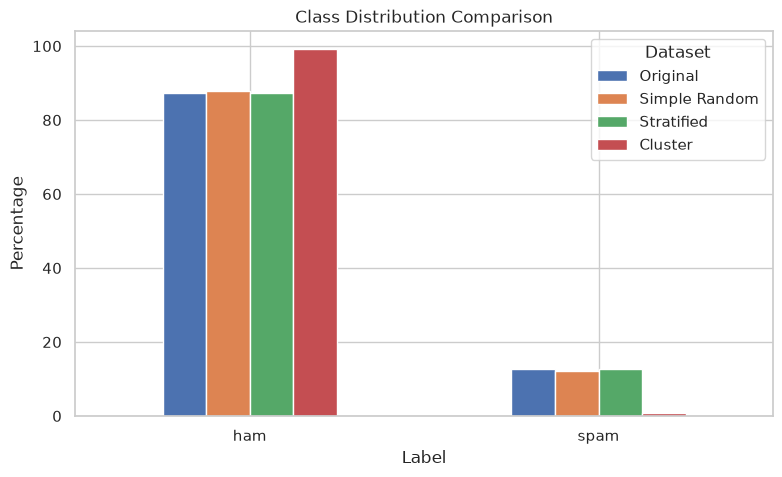

In [7]:

# Calculate label percentages
original = df["label"].value_counts(normalize=True) * 100

simple = simple_sample["label"].value_counts(normalize=True) * 100

stratified = stratified_sample["label"].value_counts(normalize=True) * 100

cluster = cluster_sample["label"].value_counts(normalize=True) * 100

# Combine results
comparison = pd.DataFrame({
    "Original": original,
    "Simple Random": simple,
    "Stratified": stratified,
    "Cluster": cluster
})

display(comparison)

# Plot the results
comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Class Distribution Comparison")
plt.xlabel("Label")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.show()


## 6. Correlation between numerical text features

These four text features measure different aspects of a message. `char_count`, `word_count` and `unique_word_count` are the strong pairs, about 0.96 to 0.98. A longer SMS usually has more words, so those counts rise together. `avg_word_length` is the weak one. It stays near 0 with the other three, and it is slightly negative with `word_count`. Correlation does not imply causation. These features are calculated from the same message, so they can move together without one causing the other.

,char_count,word_count,unique_word_count,avg_word_length
char_count,1.000000,0.973673,0.963712,0.131445
word_count,0.973673,1.000000,0.981166,-0.022504
unique_word_count,0.963712,0.981166,1.000000,-0.009806
avg_word_length,0.131445,-0.022504,-0.009806,1.000000


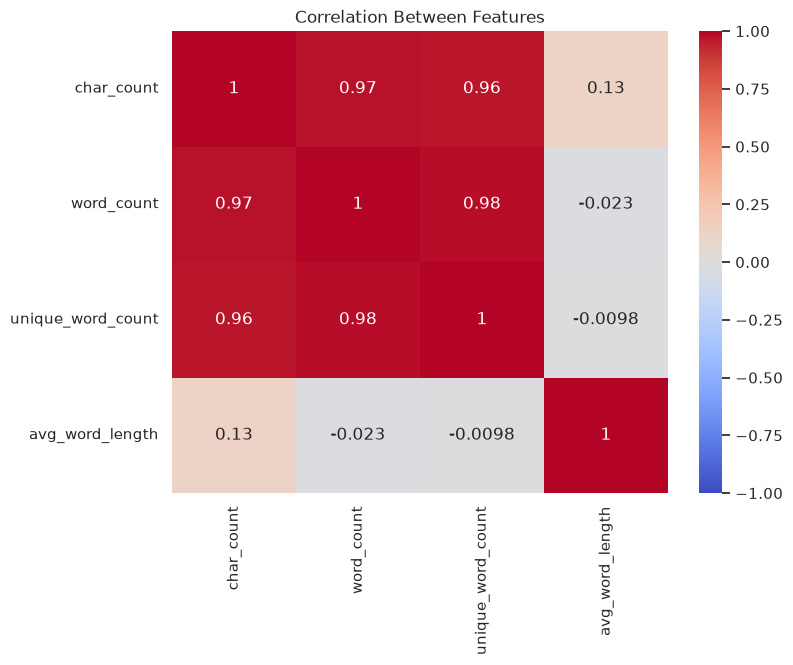

Saved ../output/cleaned_data.csv
Saved ../output/figures/correlation_heatmap.png


In [8]:

numeric_features = [
    "char_count",
    "word_count",
    "unique_word_count",
    "avg_word_length"
]

correlation = df[numeric_features].corr()
display(correlation)
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Features")

output_dir = Path("../output")
figures_dir = output_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

heatmap_path = figures_dir / "correlation_heatmap.png"
plt.savefig(heatmap_path, bbox_inches="tight")
plt.show()

df.to_csv(output_dir / "cleaned_data.csv", index=False)
print("Saved", output_dir / "cleaned_data.csv")
print("Saved", heatmap_path)


## 7. Cleaning the message text

`clean_text` only strips spaces. `cleaned_text` is the column used from here on: lowercase, URLs removed, digits removed, punctuation removed, extra spaces collapsed. The original `text` column is left as it is. Missing text is turned into an empty string before cleaning. Empty rows were already dropped above, so this is only a guard.


In [9]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    ConfusionMatrixDisplay,
    silhouette_score,
)
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

def clean_sms(value):
    text = "" if pd.isna(value) else str(value)
    text = text.lower()
    text = re.sub(r"&[a-z]+;", " ", text)
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["cleaned_text"] = df["text"].map(clean_sms)

tokens = df["cleaned_text"].str.split().explode()
tokens = tokens[tokens.notna() & (tokens != "")]
words_per_row = df["cleaned_text"].str.split().str.len()

print("Total tokens:", int(tokens.shape[0]))
print("Unique words:", int(tokens.nunique()))
print("Average words per record:", round(float(words_per_row.mean()), 2))
print("Rows empty after cleaning:", int((df["cleaned_text"] == "").sum()))


Total tokens: 77738
Unique words: 7909
Average words per record: 15.03
Rows empty after cleaning: 3


## 8. Most common words

Counts use `cleaned_text`. The first list is dominated by stop words (`the`, `to`, `a`), so the same top 20 is shown again after those words are removed. The saved chart is that comparison.


Before stop-word removal


,count
cleaned_text,
to,2080
you,2063
the,1249
and,930
in,835
is,799
me,758
my,692
for,666


After stop-word removal


,count
cleaned_text,
i'm,378
just,350
ur,322
ok,259
free,253
know,244
like,236
got,234
good,229


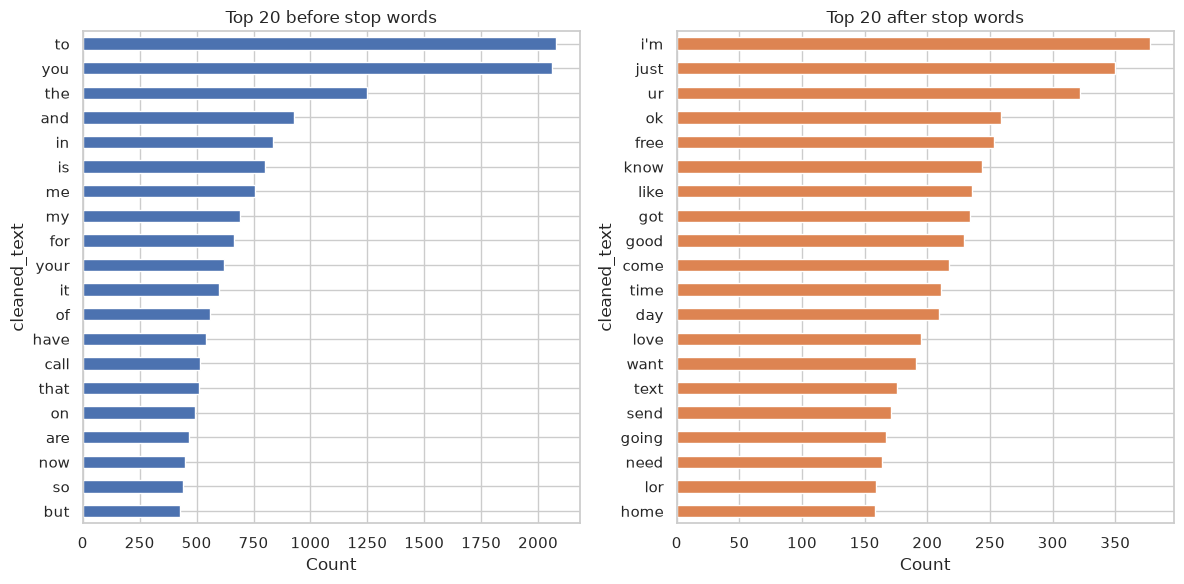

Saved ../output/figures/word_frequency.png


In [10]:
def top_words(series, n=20, drop_stops=False):
    bag = series.str.split().explode()
    bag = bag[bag.notna() & (bag != "")]
    # shortcut: one-letter leftovers ("u", "s") are dropped from the ranking; count them again if shorthand should stay
    bag = bag[bag.str.len() > 1]
    if drop_stops:
        bag = bag[~bag.isin(ENGLISH_STOP_WORDS)]
    return bag.value_counts().head(n)

before = top_words(df["cleaned_text"], 20, drop_stops=False)
after = top_words(df["cleaned_text"], 20, drop_stops=True)

print("Before stop-word removal")
display(before.to_frame("count"))
print("After stop-word removal")
display(after.to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
before.sort_values().plot.barh(ax=axes[0], color="#4c72b0")
after.sort_values().plot.barh(ax=axes[1], color="#dd8452")
axes[0].set_title("Top 20 before stop words")
axes[1].set_title("Top 20 after stop words")
axes[0].set_xlabel("Count")
axes[1].set_xlabel("Count")
fig.tight_layout()

word_chart = figures_dir / "word_frequency.png"
fig.savefig(word_chart, bbox_inches="tight")
plt.show()
print("Saved", word_chart)


## 9. Ham and spam

The two groups are the labels. Average length uses `char_count` and average word count uses `word_count`, both from the original message. The word lists are the 10 most common words in each group after stop words are removed. Each insight below has an observation, the number it comes from, and what that number means.


,char_count,word_count
label,,
ham,70.894865,14.233289
spam,137.710567,23.739663


Top 10 in ham


,count
cleaned_text,
i'm,370
just,282
ok,254
got,228
know,226
like,224
good,217
come,215
ur,203


Top 10 in spam


,count
cleaned_text,
free,197
txt,138
ur,119
stop,116
mobile,111
text,108
claim,96
reply,96
prize,82


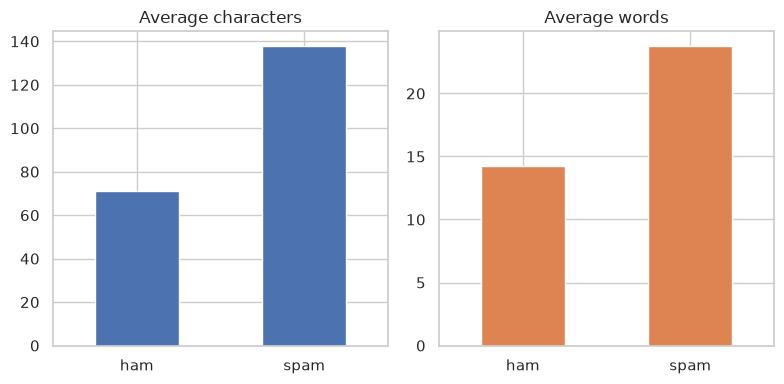

Saved ../output/figures/group_comparison.png
1. Spam messages are longer than ham messages.
Evidence: Mean characters: spam 137.7, ham 70.9. Mean words: spam 23.7, ham 14.2.
Interpretation: Spam tries to fit an offer, a phone number, or a link. Ham is often a short reply.

2. The raw word list is mostly stop words.
Evidence: Before removal the leading words are: to, you, the, and, in.
Interpretation: Those words appear in both classes, so they do not say what a message is about.

3. After stop words are removed, spam words look like ads and contact details.
Evidence: Top spam words: free, txt, ur, stop, mobile.
Interpretation: A spam filter can lean on a small set of content words.

4. Ham words look like ordinary conversation.
Evidence: Top ham words: i'm, just, ok, got, know.
Interpretation: The two classes differ in content, not only in length.

5. Ham is the large majority.
Evidence: Ham is 87.4% of the rows and spam is 12.6%.
Interpretation: Accuracy can look high if the model cal

In [11]:
group_means = df.groupby("label", observed=True)[["char_count", "word_count"]].mean()
display(group_means)

for name, part in df.groupby("label", observed=True):
    print("Top 10 in", name)
    display(top_words(part["cleaned_text"], 10, drop_stops=True).to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
group_means["char_count"].plot(kind="bar", ax=axes[0], color="#4c72b0")
group_means["word_count"].plot(kind="bar", ax=axes[1], color="#dd8452")
axes[0].set_title("Average characters")
axes[1].set_title("Average words")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()

group_chart = figures_dir / "group_comparison.png"
fig.savefig(group_chart, bbox_inches="tight")
plt.show()
print("Saved", group_chart)

ham_len = group_means.loc["ham", "char_count"]
spam_len = group_means.loc["spam", "char_count"]
ham_words = group_means.loc["ham", "word_count"]
spam_words = group_means.loc["spam", "word_count"]
ham_share = (df["label"] == "ham").mean() * 100
spam_share = (df["label"] == "spam").mean() * 100
before_top = ", ".join(before.head(5).index)
spam_top = ", ".join(top_words(df.loc[df["label"] == "spam", "cleaned_text"], 5, True).index)
ham_top = ", ".join(top_words(df.loc[df["label"] == "ham", "cleaned_text"], 5, True).index)

def insight(number, observation, evidence, interpretation):
    print(f"{number}. {observation}")
    print(f"Evidence: {evidence}")
    print(f"Interpretation: {interpretation}")
    print()

insight(
    1,
    "Spam messages are longer than ham messages.",
    f"Mean characters: spam {spam_len:.1f}, ham {ham_len:.1f}. Mean words: spam {spam_words:.1f}, ham {ham_words:.1f}.",
    "Spam tries to fit an offer, a phone number, or a link. Ham is often a short reply.",
)
insight(
    2,
    "The raw word list is mostly stop words.",
    f"Before removal the leading words are: {before_top}.",
    "Those words appear in both classes, so they do not say what a message is about.",
)
insight(
    3,
    "After stop words are removed, spam words look like ads and contact details.",
    f"Top spam words: {spam_top}.",
    "A spam filter can lean on a small set of content words.",
)
insight(
    4,
    "Ham words look like ordinary conversation.",
    f"Top ham words: {ham_top}.",
    "The two classes differ in content, not only in length.",
)
insight(
    5,
    "Ham is the large majority.",
    f"Ham is {ham_share:.1f}% of the rows and spam is {spam_share:.1f}%.",
    "Accuracy can look high if the model calls most messages ham. Spam precision and recall show whether it finds spam.",
)


## 10. Classifying spam

The target is `label`. The split is 80/20 and stratified, so the test set keeps the ham/spam mix. TF-IDF turns `cleaned_text` into word weights, then one Multinomial Naive Bayes model is trained. Results go to `output/model_metrics.txt`.


Accuracy: 0.9662
Weighted precision: 0.967
Weighted recall: 0.9662
Weighted F1: 0.9641


,precision,recall,f1,support
ham,0.963714,0.998894,0.980989,904
spam,0.989796,0.740458,0.847162,131


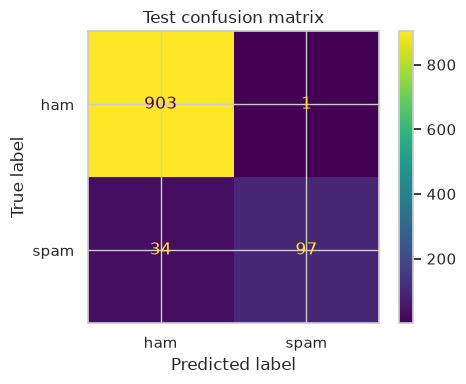

Saved ../output/figures/confusion_matrix.png
Saved ../output/model_metrics.txt


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    df["cleaned_text"],
    df["label"],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"],
)

tfidf = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)(?:[a-z]{2,}(?:'[a-z]+)?|[a-z]'[a-z]+)")
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

model = MultinomialNB()
model.fit(X_train_vec, y_train)
pred = model.predict(X_test_vec)

accuracy = accuracy_score(y_test, pred)
precision_w, recall_w, f1_w, _ = precision_recall_fscore_support(
    y_test, pred, average="weighted"
)
precision_c, recall_c, f1_c, support_c = precision_recall_fscore_support(
    y_test, pred, average=None, labels=model.classes_
)

print("Accuracy:", round(accuracy, 4))
print("Weighted precision:", round(precision_w, 4))
print("Weighted recall:", round(recall_w, 4))
print("Weighted F1:", round(f1_w, 4))

per_class = pd.DataFrame({
    "precision": precision_c,
    "recall": recall_c,
    "f1": f1_c,
    "support": support_c,
}, index=model.classes_)
display(per_class)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax)
ax.set_title("Test confusion matrix")
fig.tight_layout()
cm_path = figures_dir / "confusion_matrix.png"
fig.savefig(cm_path, bbox_inches="tight")
plt.show()
print("Saved", cm_path)

metrics_path = output_dir / "model_metrics.txt"
metrics_lines = [
    "Model: MultinomialNB",
    "Features: TF-IDF on cleaned_text, English stop words removed",
    "Split: stratified 80/20, random_state=42",
    f"Accuracy: {accuracy:.4f}",
    f"Precision (weighted): {precision_w:.4f}",
    f"Recall (weighted): {recall_w:.4f}",
    f"F1 (weighted): {f1_w:.4f}",
    "",
    "Per class:",
]
for label, p, r, f, n in zip(model.classes_, precision_c, recall_c, f1_c, support_c):
    metrics_lines.append(
        f"  {label}: precision {p:.4f}, recall {r:.4f}, f1 {f:.4f}, support {int(n)}"
    )
metrics_lines += [
    "",
    "Reading: weighted accuracy is high because ham is most of the test set.",
    "Spam recall is the stricter number. Missed spam is the costly error here.",
    "Limitation: the ham majority inflates accuracy, and TF-IDF ignores word order.",
]
metrics_path.write_text("\n".join(metrics_lines) + "\n")
print("Saved", metrics_path)


## 11. K-Means

K-Means does not use `label`. Messages are turned into TF-IDF, then reduced to 50 SVD components so distances are usable. k is whichever of 2, 3, 4, 5, 6 has the highest silhouette. A cluster id is not a class id.


In [13]:
tfidf_all = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)(?:[a-z]{2,}(?:'[a-z]+)?|[a-z]'[a-z]+)")
X_all = tfidf_all.fit_transform(df["cleaned_text"])
X_svd = TruncatedSVD(n_components=50, random_state=RANDOM_STATE).fit_transform(X_all)

tried = []
for k in (2, 3, 4, 5, 6):
    trial = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    trial_labels = trial.fit_predict(X_svd)
    score = silhouette_score(X_svd, trial_labels)
    tried.append((k, score))
    print(f"k={k} silhouette={score:.4f}")

best_k, best_score = max(tried, key=lambda row: row[1])
print("Chosen k:", best_k)

km = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df["cluster"] = km.fit_predict(X_svd)

sizes = df["cluster"].value_counts().sort_index()
print("Cluster sizes:")
display(sizes.to_frame("records"))

mix = pd.crosstab(df["cluster"], df["label"], normalize="index") * 100
print("Label mix inside each cluster (%):")
display(mix.round(1))

terms = tfidf_all.get_feature_names_out()
top_terms = {}
for cid in range(best_k):
    mask = (df["cluster"] == cid).to_numpy()
    centroid = np.asarray(X_all[mask].mean(axis=0)).ravel()
    top_terms[cid] = list(terms[centroid.argsort()[::-1][:8]])
    print(f"Cluster {cid}: {', '.join(top_terms[cid])}")

summary = [
    f"k: {best_k}",
    "How k was chosen: highest silhouette on a 50-component SVD of TF-IDF, trying k = 2, 3, 4, 5, 6. k was not fixed at 3.",
    f"Silhouette: {best_score:.4f}",
    "",
    "Sizes:",
]
for cid, count in sizes.items():
    summary.append(f"  cluster {cid}: {int(count)} records")
summary += ["", "Label mix (row percent). Cluster id is not class id:"]
for cid, row in mix.round(1).iterrows():
    parts = ", ".join(f"{col} {val}%" for col, val in row.items())
    summary.append(f"  cluster {cid}: {parts}")
summary += ["", "Top terms:"]
for cid, words in top_terms.items():
    summary.append(f"  cluster {cid}: {', '.join(words)}")
notes = []
for cid, row in mix.iterrows():
    majority = row.idxmax()
    notes.append(
        f"Cluster {cid} is {row[majority]:.0f}% {majority}. Leading terms: {', '.join(top_terms[cid][:5])}."
    )
small = sizes.idxmin()
large = sizes.idxmax()
if best_k == 2:
    notes.append(
        f"Cluster {small} is the small group ({int(sizes[small])} rows). Its terms are short replies, and spam is only {mix.loc[small, 'spam']:.1f}% of it."
    )
    notes.append(
        f"Cluster {large} is everything else. Spam is {mix.loc[large, 'spam']:.1f}% of it, but ham still sets the average, so the top terms stay conversational."
    )
else:
    notes.append("The groups follow wording, not the spam label. Each cluster is still mostly ham.")
notes.append("K-Means never saw the label, and a cluster number is not a class code.")
summary += ["", "Reading:"] + notes
summary_path = output_dir / "cluster_summary.txt"
summary_path.write_text("\n".join(summary) + "\n")
print("Saved", summary_path)

# rewritten so cleaned_text and cluster are in the file person 2 saved earlier
df.to_csv(output_dir / "cleaned_data.csv", index=False)
print("Saved", output_dir / "cleaned_data.csv")


k=2 silhouette=0.1965


k=3 silhouette=0.1467


k=4 silhouette=0.1390


k=5 silhouette=0.1481


k=6 silhouette=0.0990
Chosen k: 2
Cluster sizes:


,records
cluster,
0,497
1,4674


Label mix inside each cluster (%):


label,ham,spam
cluster,,
0,99.2,0.8
1,86.1,13.9


Cluster 0: ok, i'm, lor, home, going, i'll, come, it's
Cluster 1: just, come, ur, know, good, got, time, like
Saved ../output/cluster_summary.txt
Saved ../output/cleaned_data.csv
